# Notebook 3 — Quantized local reduced-order models (ql-ROM)

Reference: A. Colanera & L. Magri, *Quantized local reduced-order modeling in time (ql-ROM)*, arXiv:2506.13738 (2025).

**The problem.** A *global* POD-Galerkin reduced-order model (g-ROM) approximates the state as the mean plus a combination of a few modes:
$\boldsymbol{u}(t) \approx \bar{\boldsymbol{u}} + \sum_{i=1}^r a_i(t)\,\boldsymbol{\varphi}_i$.
This is an approximation with **a single linear subspace** for the whole set of states visited by the system. If this set has a complicated geometry (curved, with very different regions), many modes are needed and the model may become inaccurate or even qualitatively wrong.

**The ql-ROM idea** (*divide and conquer*):

1. **quantize** the phase space with K-means (Notebook 1), obtaining $K$ cells with centroids $\boldsymbol{c}_k$;
2. build a **local POD-Galerkin model** in each cell, centered at the centroid and using the POD modes of the cell;
3. during the simulation, use the model of the cell where the state is and **change basis** when the state moves to another cell.

Unlike the CNM (Notebook 2), which is purely data-driven, the ql-ROM is **intrusive**: the dynamics in each cell comes from the projection of the governing equations.

**Contents**

1. Local POD-Galerkin for quadratic systems: theory and implementation.
2. Lorenz system: can planar models reproduce a chaotic attractor?
3. Summary.

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

plt.rcParams.update({"figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3, "font.size": 11})

## 1. Local POD-Galerkin for quadratic systems

The Lorenz system, like many fluid-dynamics models (e.g. the Navier–Stokes equations), has the form

$$\dot{\boldsymbol{u}} = \mathcal{A}\boldsymbol{u} + \mathcal{N}(\boldsymbol{u}), \qquad \boldsymbol{u}\in\mathbb{R}^N,$$

with $\mathcal{A}$ linear and $\mathcal{N}$ **quadratic**. For Lorenz ($N = 3$), $\mathcal{A}$ is a $3\times3$ matrix and $\mathcal{N}(\boldsymbol{u}) = (0,\,-xz,\,xy)$.

A quadratic function is described by a symmetric bilinear form $\mathcal{H}$, with $\mathcal{N}(\boldsymbol{u}) = \mathcal{H}(\boldsymbol{u}, \boldsymbol{u})$. We can compute it from $\mathcal{N}$ alone (polarization identity):

$$\mathcal{H}(\boldsymbol{u}, \boldsymbol{v}) = \tfrac14\big[\mathcal{N}(\boldsymbol{u}+\boldsymbol{v}) - \mathcal{N}(\boldsymbol{u}-\boldsymbol{v})\big].$$

### 1.1 Projection in one cluster

In cluster $k$ we approximate the state as

$$\boldsymbol{u}(t) \approx \boldsymbol{c}_k + \boldsymbol{U}_k\,\boldsymbol{a}(t), \qquad \boldsymbol{U}_k \in \mathbb{R}^{N\times r},$$

where the columns $\boldsymbol{\varphi}_i$ of $\boldsymbol{U}_k$ are the first $r$ POD modes of the **fluctuations with respect to the centroid**, $\boldsymbol{u}_m - \boldsymbol{c}_k$, computed with the SVD of the snapshots of that cluster only. Substituting into the equation and projecting onto $\boldsymbol{U}_k$ (Galerkin):

$$\dot{\boldsymbol{a}} = \underbrace{\boldsymbol{U}_k^\top\big(\mathcal{A}\boldsymbol{c}_k + \mathcal{N}(\boldsymbol{c}_k)\big)}_{\boldsymbol{f}_k}
+ \underbrace{\boldsymbol{U}_k^\top\big(\mathcal{A}\boldsymbol{U}_k + 2\,\mathcal{H}(\boldsymbol{c}_k, \boldsymbol{U}_k)\big)}_{\boldsymbol{L}_k}\,\boldsymbol{a}
+ \boldsymbol{\mathsf{Q}}_k(\boldsymbol{a}, \boldsymbol{a}),
\qquad
\big[\boldsymbol{\mathsf{Q}}_k\big]_{ijl} = \boldsymbol{\varphi}_i^\top \mathcal{H}(\boldsymbol{\varphi}_j, \boldsymbol{\varphi}_l).$$

All reduced operators ($\boldsymbol{f}_k$, $\boldsymbol{L}_k$, $\boldsymbol{\mathsf{Q}}_k$) are computed once (**offline**). During the simulation (**online**) the cost per step is $O(r^3)$ and does not depend on $N$.

Compared with the g-ROM there are two new features: the centroid $\boldsymbol{c}_k$ generates the forcing $\boldsymbol{f}_k$ and part of the linear term, and each cluster has its own set of operators.

### 1.2 Switching clusters

If at the next step the reconstructed state is closer to centroid $\boldsymbol{c}_j$ than to $\boldsymbol{c}_i$, we switch to model $j$ with the change of coordinates (eq. 14 of the paper)

$$\boldsymbol{a}_j = \boldsymbol{U}_j^\top \boldsymbol{U}_i\,\boldsymbol{a}_i + \boldsymbol{U}_j^\top(\boldsymbol{c}_i - \boldsymbol{c}_j),$$

i.e. we project the state $\boldsymbol{c}_i + \boldsymbol{U}_i\boldsymbol{a}_i$ onto the new basis. The matrices $\boldsymbol{U}_j^\top\boldsymbol{U}_i$ and the vectors $\boldsymbol{U}_j^\top(\boldsymbol{c}_i - \boldsymbol{c}_j)$ are computed offline.

With $K = 1$ and $\boldsymbol{c}_1 = \bar{\boldsymbol{u}}$ (mean of the snapshots) we recover the **classical global POD-Galerkin model**: g-ROM and ql-ROM are the same code.

We integrate both the full-order model (FOM) and the ROMs with the classical fourth-order Runge–Kutta method (RK4).

In [8]:
def rk4_step(f, u, dt):
    k1 = f(u)
    k2 = f(u + 0.5 * dt * k1)
    k3 = f(u + 0.5 * dt * k2)
    k4 = f(u + dt * k3)
    return u + dt / 6 * (k1 + 2 * k2 + 2 * k3 + k4)


def simulate(f, u0, dt, n_steps, save_every=1):
    u = u0.copy()
    out = [u.copy()]
    for n in range(1, n_steps + 1):
        u = rk4_step(f, u, dt)
        if n % save_every == 0:
            out.append(u.copy())
    return np.array(out)


class LocalROM:
    # Galerkin model of du/dt = A(u) + N(u) around the centroid c, with orthonormal basis U (N x r).
    # A and N must accept a vector or a matrix whose columns are states.

    def __init__(self, A, N, c, U):
        r = U.shape[1]
        H = lambda u, v: 0.25 * (N(u + v) - N(u - v))          # symmetric bilinear form (polarization)
        self.c, self.U = c, U
        self.f = U.T @ (A(c) + N(c))
        self.L = U.T @ (A(U) + 2 * H(c[:, None], U))
        Uj, Ul = np.repeat(U, r, axis=1), np.tile(U, (1, r))    # all pairs of modes (j, l)
        self.Q = (U.T @ H(Uj, Ul)).reshape(r, r, r)

    def rhs(self, a):
        return self.f + self.L @ a + np.einsum("ijl,j,l->i", self.Q, a, a)


def build_qlrom(A, N, X, K, r, seed=0):
    # offline: clustering, local POD, reduced operators, change-of-basis matrices
    if K == 1:
        cents, labels = X.mean(0, keepdims=True), np.zeros(len(X), int)
    else:
        km = KMeans(K, n_init=10, random_state=seed).fit(X)
        cents, labels = km.cluster_centers_, km.labels_
    roms = []
    for k in range(K):
        U = np.linalg.svd((X[labels == k] - cents[k]).T, full_matrices=False)[0][:, :r]
        roms.append(LocalROM(A, N, cents[k], U))
    switch_U = [[roms[j].U.T @ roms[i].U for j in range(K)] for i in range(K)]
    switch_c = [[roms[j].U.T @ (cents[i] - cents[j]) for j in range(K)] for i in range(K)]
    return dict(cents=cents, labels=labels, roms=roms, switch_U=switch_U, switch_c=switch_c)


def nearest(cents, u):
    return int(np.argmin(((cents - u) ** 2).sum(axis=1)))


def run_qlrom(model, u0, dt, n_steps, save_every=1, blowup=1e3):
    # online: integrate the model of the active cell and change basis when the state changes cell
    cents, roms = model["cents"], model["roms"]
    k = nearest(cents, u0)
    a = roms[k].U.T @ (u0 - cents[k])
    U_out, k_out = [u0.copy()], [k]
    for n in range(1, n_steps + 1):
        a = rk4_step(roms[k].rhs, a, dt)
        u = cents[k] + roms[k].U @ a
        if not np.all(np.isfinite(u)) or np.abs(u).max() > blowup:   # the ROM has blown up
            n_left = n_steps // save_every + 1 - len(U_out)
            U_out += [np.full_like(u0, np.nan)] * n_left
            k_out += [-1] * n_left
            break
        k_new = nearest(cents, u)
        if k_new != k:
            a = model["switch_U"][k][k_new] @ a + model["switch_c"][k][k_new]
            k = k_new
        if n % save_every == 0:
            U_out.append(u); k_out.append(k)
    return np.array(U_out), np.array(k_out)

## 2. Lorenz system

$$\dot x = \sigma(y-x), \qquad \dot y = x(\rho - z) - y, \qquad \dot z = xy - bz, \qquad \sigma = 10,\ \rho = 28,\ b = 8/3.$$

In the form $\dot{\boldsymbol{u}} = \mathcal{A}\boldsymbol{u} + \mathcal{N}(\boldsymbol{u})$:

$$\mathcal{A} = \begin{pmatrix} -\sigma & \sigma & 0 \\ \rho & -1 & 0 \\ 0 & 0 & -b \end{pmatrix}, \qquad \mathcal{N}(\boldsymbol{u}) = \begin{pmatrix} 0 \\ -xz \\ xy \end{pmatrix}.$$

We integrate with $\Delta t = 0.005$, discard a transient of 20 time units, and use 200 time units for training and the following 200 for testing.

In [9]:
sigma, rho, b = 10.0, 28.0, 8.0 / 3.0
A_lor = np.array([[-sigma, sigma, 0.0], [rho, -1.0, 0.0], [0.0, 0.0, -b]])

def A_lorenz(u):
    return A_lor @ u

def N_lorenz(u):
    x, y, z = u[0], u[1], u[2]
    return np.stack([0 * x, -x * z, x * y])

dt_l = 0.005
U_lor = simulate(lambda u: A_lorenz(u) + N_lorenz(u), np.array([1.0, 1.0, 1.0]), dt_l, int(520 / dt_l))
U_lor = U_lor[int(20 / dt_l):]
n_tr = int(400 / dt_l)
XL_train, XL_test = U_lor[:n_tr], U_lor[n_tr:]
print("training:", XL_train.shape, " test:", XL_test.shape)

training: (80000, 3)  test: (20001, 3)


### 2.1 One plane or many planes?

We now use $r = 2$: each model lives on a **plane**. The global model uses a single plane through the mean of the attractor; the ql-ROM uses $K = 10$ planes, one per cluster, each centered at its centroid and aligned with the local principal directions.

relative reconstruction error of the test data with r = 2:  global 4.0e-02   local (K = 10) 3.1e-03


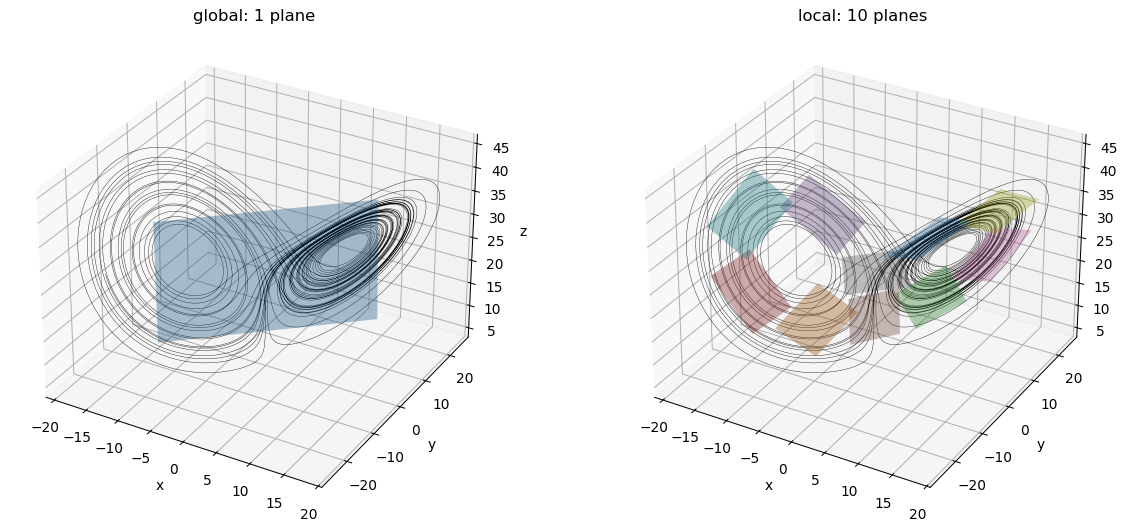

In [10]:
K_l, r_l = 10, 2
g_lor = build_qlrom(A_lorenz, N_lorenz, XL_train, K=1, r=r_l)
q_lor = build_qlrom(A_lorenz, N_lorenz, XL_train, K=K_l, r=r_l)

def reconstruction_error(model, X):
    cents = model["cents"]
    lab = np.argmin(((X[:, None, :] - cents[None]) ** 2).sum(-1), axis=1)
    err = 0.0
    for k, rom in enumerate(model["roms"]):
        D = X[lab == k] - cents[k]
        err += np.sum((D - (D @ rom.U) @ rom.U.T) ** 2)
    return err / np.sum((X - X.mean(0)) ** 2)

print(f"relative reconstruction error of the test data with r = 2:  "
      f"global {reconstruction_error(g_lor, XL_test):.1e}   local (K = {K_l}) {reconstruction_error(q_lor, XL_test):.1e}")

def draw_plane(ax, c, U, size, color):
    s = np.linspace(-1, 1, 2)
    S1, S2 = np.meshgrid(s, s)
    P = c[:, None, None] + size[0] * U[:, 0, None, None] * S1 + size[1] * U[:, 1, None, None] * S2
    ax.plot_surface(*P, color=color, alpha=0.35, linewidth=0)

fig = plt.figure(figsize=(14, 6))
for i, (model, title) in enumerate([(g_lor, "global: 1 plane"), (q_lor, f"local: {K_l} planes")]):
    ax = fig.add_subplot(1, 2, i + 1, projection="3d")
    ax.plot(*XL_train[:8000].T, "k", lw=0.3)
    for k, rom in enumerate(model["roms"]):
        Xk = XL_train[model["labels"] == k] - rom.c
        size = 1.5 * np.sqrt(np.mean((Xk @ rom.U) ** 2, axis=0))     # patch size ~ local spread
        draw_plane(ax, rom.c, rom.U, size, plt.cm.tab10(k % 10))
    ax.set_title(title); ax.set_xlabel("x"); ax.set_ylabel("y"); ax.set_zlabel("z")
plt.tight_layout(); plt.show()

### 2.2 g-ROM versus ql-ROM with $r = 2$

We integrate both models for 100 time units, starting from the first test snapshot.

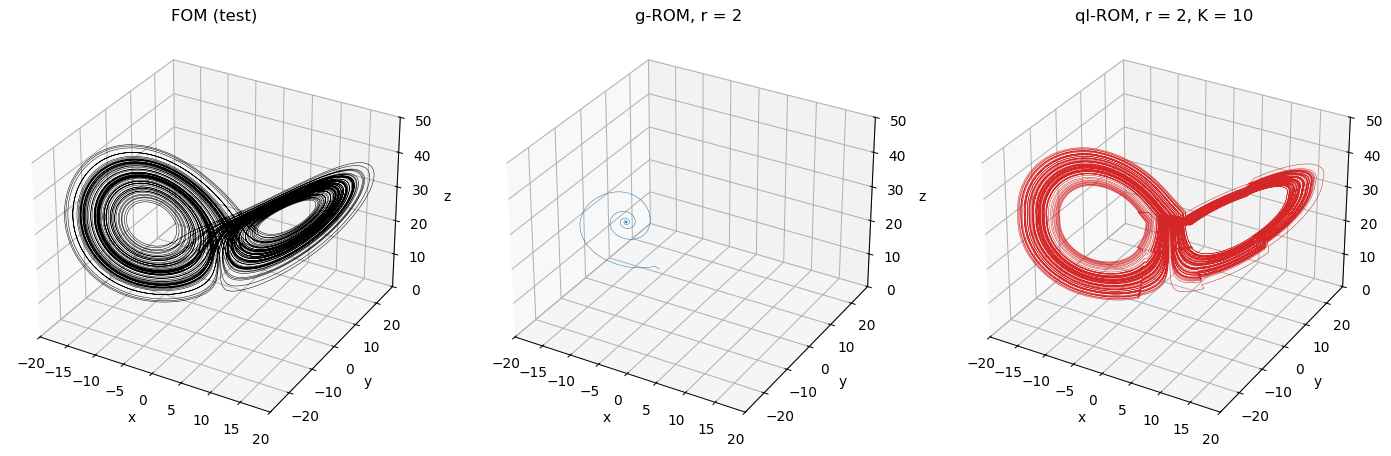

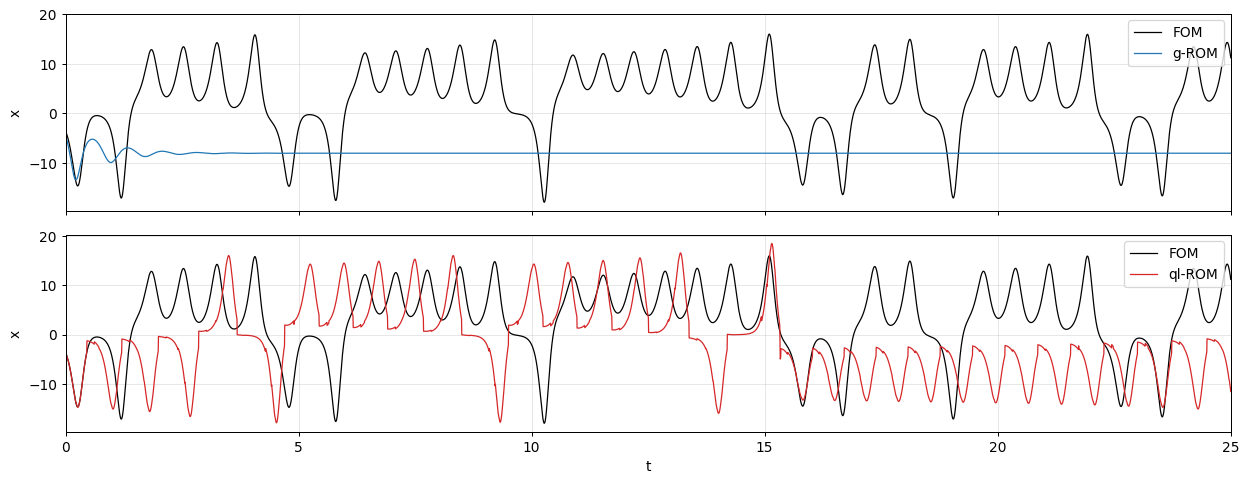

In [11]:
T_lor = 100
U_g, _ = run_qlrom(g_lor, XL_test[0], dt_l, int(T_lor / dt_l))
U_q, k_q = run_qlrom(q_lor, XL_test[0], dt_l, int(T_lor / dt_l))
U_t = XL_test[:int(T_lor / dt_l) + 1]

fig = plt.figure(figsize=(16, 5))
for i, (U, title, col) in enumerate([(U_t, "FOM (test)", "k"), (U_g, "g-ROM, r = 2", "tab:blue"),
                                     (U_q, f"ql-ROM, r = 2, K = {K_l}", "tab:red")]):
    ax = fig.add_subplot(1, 3, i + 1, projection="3d")
    ax.plot(*U.T, color=col, lw=0.4)
    ax.set_xlim(-20, 20); ax.set_ylim(-28, 28); ax.set_zlim(0, 50)
    ax.set_title(title); ax.set_xlabel("x"); ax.set_ylabel("y"); ax.set_zlabel("z")
plt.tight_layout(); plt.show()

tt = np.arange(len(U_t)) * dt_l
fig, ax = plt.subplots(2, 1, figsize=(14, 5.5), sharex=True)
for a, U, name, col in [(ax[0], U_g, "g-ROM", "tab:blue"), (ax[1], U_q, "ql-ROM", "tab:red")]:
    a.plot(tt, U_t[:, 0], "k", lw=1, label="FOM")
    a.plot(tt, U[:, 0], color=col, lw=1, label=name)
    a.set_ylabel("x"); a.legend(loc="upper right"); a.set_xlim(0, 25)
ax[1].set_xlabel("t")
plt.tight_layout(); plt.show()

**What we observe.**

- The **g-ROM** spirals onto a fixed point. This is not a numerical accident: a 2D autonomous ODE cannot be chaotic (Poincaré–Bendixson theorem). Its trajectories can only converge to fixed points or periodic orbits.
- The **ql-ROM** uses 2D models too, but it switches between 10 different planes. The switched system is no longer a single 2D autonomous ODE, and it reproduces the butterfly: oscillations of growing amplitude on each wing and irregular jumps between the wings.
- Pointwise prediction is lost after a few oscillations, as for any model of a chaotic system (here also because each local plane is only an approximation of the attractor).

The correct comparison is therefore **statistical**: probability distributions of $x$ and $z$, and the frequency of the jumps between the wings.

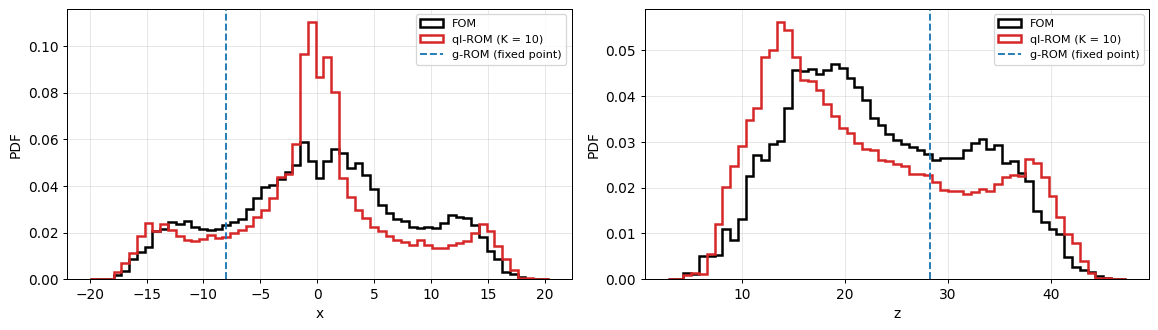

jumps between wings per unit time:  FOM 0.57   ql-ROM 0.54
mean and std of z:  FOM 23.5 ± 8.7   ql-ROM 22.3 ± 9.7


In [12]:
U_long, _ = run_qlrom(q_lor, XL_test[0], dt_l, len(XL_test) - 1)

def wing_switches_per_unit_time(U, dt):
    return np.count_nonzero(np.diff(np.sign(U[:, 0]))) / (len(U) * dt)

fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
for i, (var, name) in enumerate([(0, "x"), (2, "z")]):
    bins = np.linspace(XL_test[:, var].min() - 2, XL_test[:, var].max() + 2, 60)
    ax[i].hist(XL_test[:, var], bins, density=True, histtype="step", color="k", lw=2, label="FOM")
    ax[i].hist(U_long[:, var], bins, density=True, histtype="step", color="tab:red", lw=2, label=f"ql-ROM (K = {K_l})")
    ax[i].axvline(U_g[-1, var], color="tab:blue", ls="--", label="g-ROM (fixed point)")
    ax[i].set_xlabel(name); ax[i].set_ylabel("PDF"); ax[i].legend(fontsize=9)
plt.tight_layout(); plt.show()

print(f"jumps between wings per unit time:  FOM {wing_switches_per_unit_time(XL_test, dt_l):.2f}   "
      f"ql-ROM {wing_switches_per_unit_time(U_long, dt_l):.2f}")
print(f"mean and std of z:  FOM {XL_test[:, 2].mean():.1f} ± {XL_test[:, 2].std():.1f}   "
      f"ql-ROM {U_long[:, 2].mean():.1f} ± {U_long[:, 2].std():.1f}")

The statistics are close to those of the FOM but not identical: the ql-ROM spends too much time near $x \approx 0$, the region between the wings where the attractor is most strongly folded and a plane is the poorest approximation. The time series also shows small kinks: at each cluster switch the state is projected onto a new plane, so the trajectory is continuous but not smooth (footnote 1 of the paper).



## 3. Summary

| | g-ROM (POD-Galerkin) | ql-ROM | CNM (Notebook 2) |
|---|---|---|---|
| **Uses the equations** | yes | yes | no |
| **Representation** | 1 affine subspace | $K$ affine subspaces, one per cell | $K$ centroids |
| **Dynamics** | reduced ODEs | local reduced ODEs + change of basis | stochastic network of transitions |
| **Lorenz, $r = 2$** | collapses to a fixed point | reproduces the butterfly | reproduces the jumps, not the amplitude growth |
| **Online cost** | $O(r^3)$ | $O(r^3)$ + affiliation | negligible |

The ql-ROM does not add degrees of freedom: at any time **only one** model of dimension $r$ is active, so its online cost is almost the same as that of the g-ROM. For a large system (for example $10^5$–$10^7$ unknowns in a 2D/3D flow) both are much cheaper than the full-order model, because their cost per step does not depend on $N$.

The three notebooks share a common element: the **quantization of the phase space** with K-means. In the CNM each cell is a node of the network; in the ql-ROM each cell hosts a local physical model.